In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score


from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

In [2]:
# Φόρτωση του df με όλες τις μεταβλητές από το 02_feature_engineering
df = pd.read_pickle("df_features.pkl")
print("Φορτώθηκε:", df.shape)

# Οι 18 δείκτες των τριών scores (ίδιοι με το 02)
f_cols   = ['ch_rsst', 'dch_rec', 'dch_inv', 'soft_assets', 'ch_cs', 'ch_roa', 'issue']   # F-Score
alt_cols = ['alt_x1', 'reoa', 'EBIT', 'alt_x4', 'alt_x5']                                 # Z-Score
ben_cols = ['ben_dsri', 'ben_gmi', 'ben_sgi', 'dpi', 'ben_lvgi', 'ben_tata']             # M-Score
score_cols = f_cols + alt_cols + ben_cols
print("Πλήθος δεικτών:", len(score_cols))

Φορτώθηκε: (108399, 56)
Πλήθος δεικτών: 18


## **TRAIN - VALIDATION - TEST SPLIT**

In [3]:
#Train χρονιες 1991-2001 και test χρονιες 2003-2008
train = df[df['fyear'] <= 2001].copy() 
test = df[df['fyear'] >= 2003].copy()

In [4]:
# Έλεγχος: πόσες γραμμές και πόσες απάτες έχει το κάθε κομμάτι
print("Train:", train.shape, "| απάτες:", train['misstate'].sum(),
      f"({train['misstate'].mean() * 100:.2f}%)")
print("Test: ", test.shape, "| απάτες:", test['misstate'].sum(),
      f"({test['misstate'].mean() * 100:.2f}%)")

Train: (67166, 56) | απάτες: 499 (0.74%)
Test:  (35166, 56) | απάτες: 261 (0.74%)


In [5]:
# Υποθέσεις απάτης που βρίσκονται στο test 
test_cases = test.loc[test['misstate'] == 1, 'p_aaer'].unique()
print("Υποθέσεις απάτης στο test:", len(test_cases))

Υποθέσεις απάτης στο test: 127


In [6]:
# Υποθέσεις απάτης που βρισκονται στο train και στο test 
serial = (train['misstate'] == 1) & (train['p_aaer'].isin(test_cases))
print("Δόλιες χρονιές στο train που ανήκουν σε υποθέσεις του test:", serial.sum())
print("Από πόσες διαφορετικές υποθέσεις:", train.loc[serial, 'p_aaer'].nunique())
print(train.loc[serial, ['gvkey', 'fyear', 'p_aaer', 'misstate']].head(10))

Δόλιες χρονιές στο train που ανήκουν σε υποθέσεις του test: 99
Από πόσες διαφορετικές υποθέσεις: 39
       gvkey  fyear  p_aaer  misstate
1711    1633   2001  3784.0         1
7091    3362   1999  2628.0         1
7092    3362   2000  2628.0         1
7093    3362   2001  2628.0         1
14361   5860   2001  2934.0         1
15089   6081   2001  3165.0         1
15329   6136   1997  2819.0         1
15330   6136   1998  2819.0         1
15331   6136   1999  2819.0         1
15332   6136   2000  2819.0         1


In [7]:
#Serial fraud: αλλαγή των ετικετών στο train 
# Οι δόλιες χρονιές του train που ανήκουν σε υποθέσεις του test γίνονται 0
train.loc[serial, 'misstate'] = 0

print("Απάτες στο train μετά την αλλαγή:", train['misstate'].sum(),
      f"({train['misstate'].mean() * 100:.2f}%)")
print("Απάτες στο test (δεν άλλαξε τίποτα):", test['misstate'].sum())

Απάτες στο train μετά την αλλαγή: 400 (0.60%)
Απάτες στο test (δεν άλλαξε τίποτα): 261


In [8]:
raw_cols = ['act','ap','at','ceq','che','cogs','csho','dlc','dltis','dltt','dp','ib',
            'invt','ivao','ivst','lct','lt','ni','ppegt','pstk','re','rect','sale',
            'sstk','txp','txt','xint','prcc_f']

        train_median  test_median  pct_change
re               1.9         -4.0      -315.2
dltis            0.4          0.0      -100.0
txt              0.5          0.3       -40.5
invt             4.6          3.3       -28.6
dltt             5.0          3.9       -22.5
dlc              1.5          1.2       -21.3
ib               0.9          0.8       -15.9
prcc_f           7.8          6.8       -11.9
ni               0.9          0.8        -9.8
xint             1.0          1.1        14.8
cogs            48.8         57.7        18.1
rect            11.2         13.8        23.3
ap               5.7          7.6        32.5
sale            77.7        103.9        33.7
dp               3.3          4.7        43.7
ppegt           30.8         45.4        47.3
lct             17.9         28.1        57.3
lt              31.8         50.6        59.0
act             38.0         62.6        64.7
at              79.9        140.8        76.1
ceq             36.0         66.6 

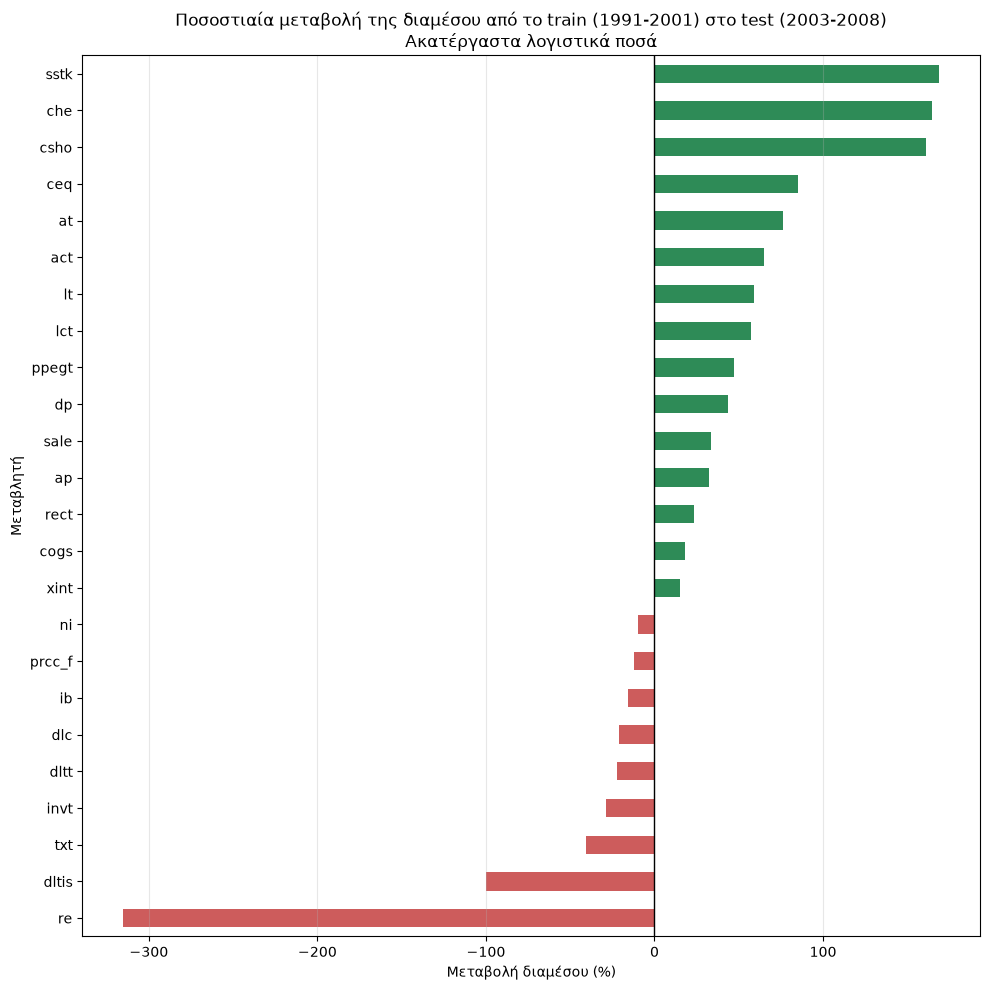

             train_median  test_median  difference
alt_x5              0.981        0.768      -0.213
reoa                0.036       -0.069      -0.105
alt_x1              0.203        0.175      -0.028
soft_assets         0.538        0.522      -0.016
EBIT                0.054        0.039      -0.015
ben_lvgi            1.012        1.006      -0.007
ch_rsst             0.033        0.027      -0.006
ben_dsri            0.988        0.982      -0.006
dch_rec             0.008        0.005      -0.003
issue               1.000        1.000       0.000
dch_inv             0.000        0.000       0.000
ch_cs               0.084        0.085       0.001
ben_gmi             0.997        0.999       0.002
ch_roa             -0.003        0.000       0.004
ben_tata           -0.041       -0.036       0.005
ben_sgi             1.087        1.095       0.008
dpi                 0.965        0.978       0.013
alt_x4              2.015        2.455       0.440


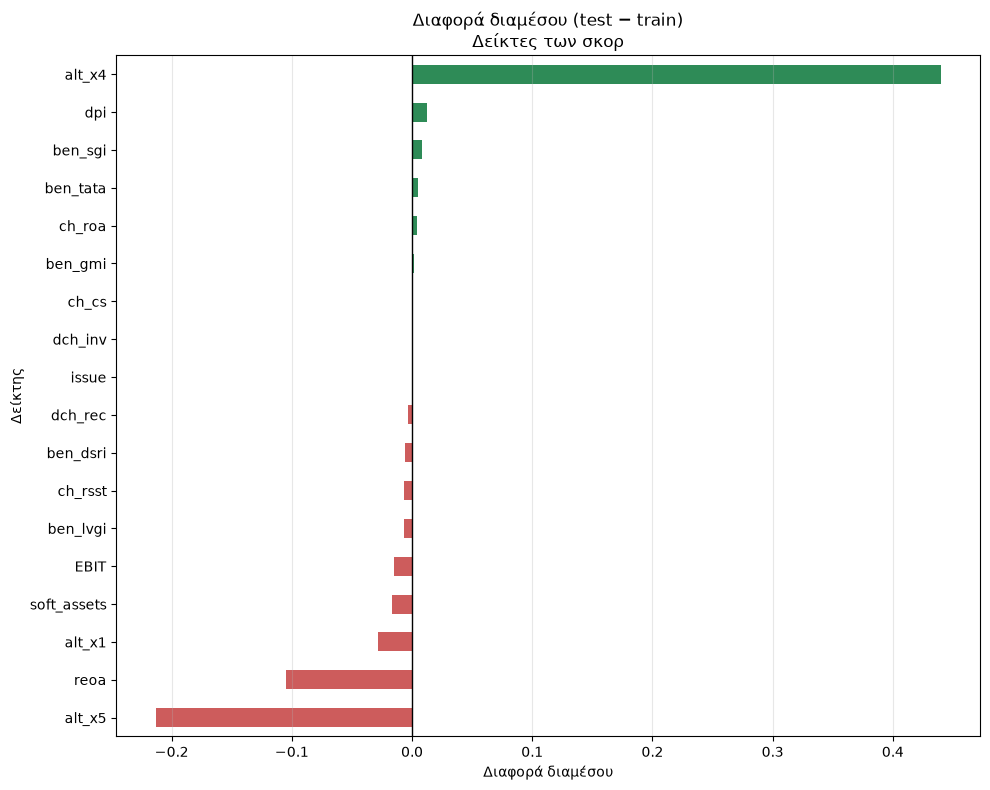

In [9]:
#  Ποσοστιαία μεταβολή raw μεταβλητών: διάμεσος σε train και test
raw_median = pd.DataFrame({
    'train_median': train[raw_cols].median(),
    'test_median':  test[raw_cols].median(),
})

# Μεταβλητές με διάμεσο 0 στο train (π.χ. ivst, pstk, txp) δεν μπορούν να
# μετρηθούν σε ποσοστό (διαίρεση με το 0), οπότε εξαιρούνται από το διάγραμμα
raw_median = raw_median[raw_median['train_median'] != 0]

raw_median['pct_change'] = (raw_median['test_median'] / raw_median['train_median'] - 1) * 100
raw_median = raw_median.sort_values('pct_change')
print(raw_median.round(1))

# Πράσινο αν αυξήθηκε στο test, κόκκινο αν μειώθηκε
colors = ['seagreen' if v > 0 else 'indianred' for v in raw_median['pct_change']]

ax = raw_median['pct_change'].plot(kind='barh', figsize=(10, 10), color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Ποσοστιαία μεταβολή της διαμέσου από το train (1991-2001) στο test (2003-2008)\nΑκατέργαστα λογιστικά ποσά')
ax.set_xlabel('Μεταβολή διαμέσου (%)')
ax.set_ylabel('Μεταβλητή')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


#  Δείκτες των σκορ: απόλυτη διαφορά 
ratio_median = pd.DataFrame({
    'train_median': train[score_cols].median(),
    'test_median':  test[score_cols].median(),
})
ratio_median['difference'] = ratio_median['test_median'] - ratio_median['train_median']
ratio_median = ratio_median.sort_values('difference')
print(ratio_median.round(3))

colors = ['seagreen' if v > 0 else 'indianred' for v in ratio_median['difference']]

ax = ratio_median['difference'].plot(kind='barh', figsize=(10, 8), color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Διαφορά διαμέσου (test − train)\nΔείκτες των σκορ')
ax.set_xlabel('Διαφορά διαμέσου')
ax.set_ylabel('Δείκτης')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

##### Παρατηρούμε πως τα raw δεδομένα παρουσιάζουν μεγάλες ποσοστιαίεες μεταβολές ανάμεσα στο train και το test ενώ οι δείκτες έχουν μικές διαφορές 

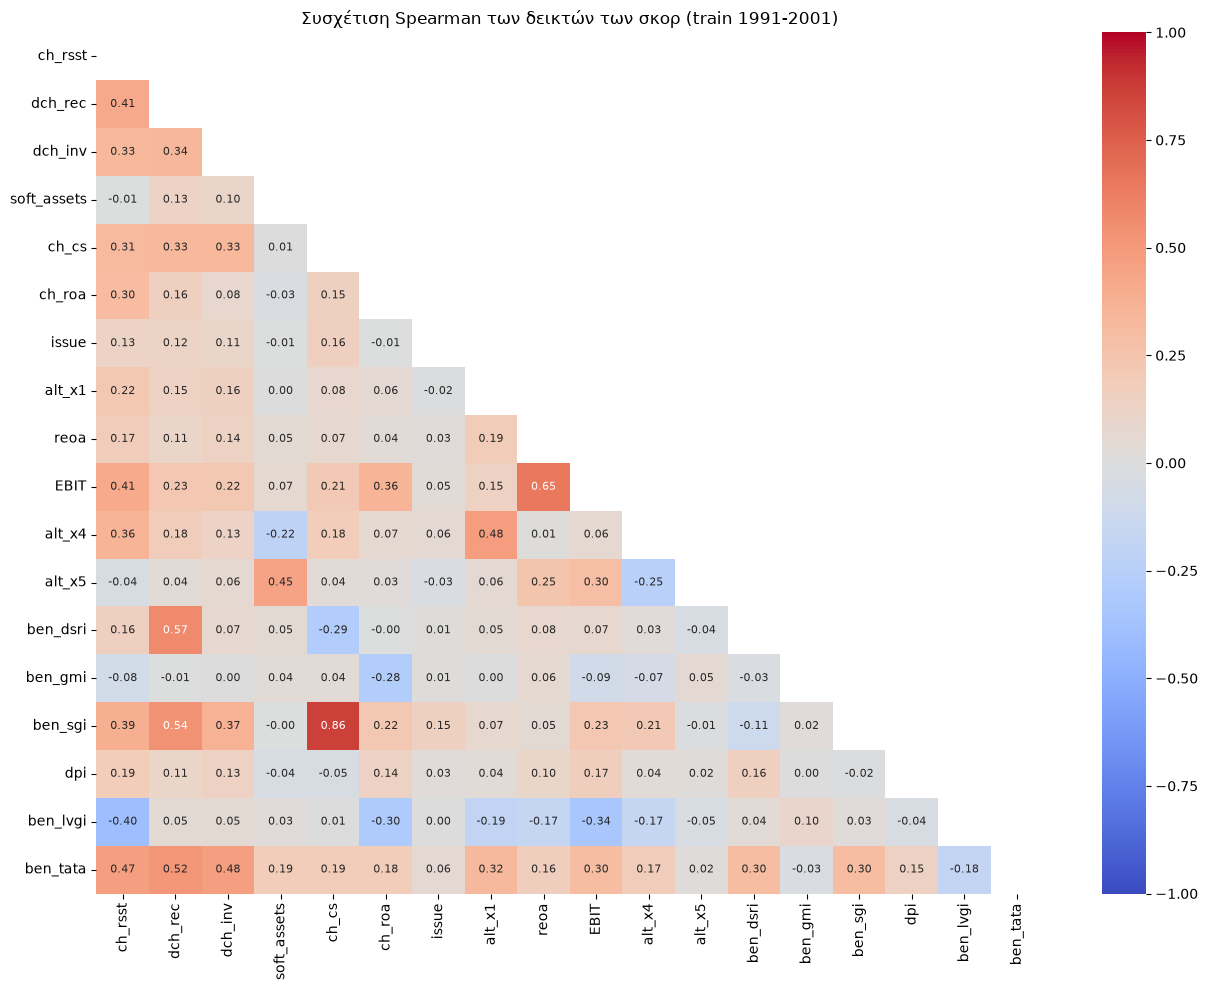

In [10]:
# Συσχέτιση Spearman των 18 δεικτών των σκορ - μόνο στο train
corr = train[score_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr,mask=mask, cmap='coolwarm', vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 8})
plt.title('Συσχέτιση Spearman των δεικτών των σκορ (train 1991-2001)')
plt.tight_layout()
plt.savefig('diagramma_sysxetisi.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
# Ζεύγη δεικτών με |συσχέτιση| >= 0.6
pairs = []
for i in range(len(score_cols)):
    for j in range(i + 1, len(score_cols)):
        value = corr.iloc[i, j]
        if abs(value) >= 0.6:
            pairs.append((score_cols[i], score_cols[j], round(value, 3)))

high_corr = pd.DataFrame(pairs, columns=['Δείκτης 1', 'Δείκτης 2', 'Spearman'])
print(high_corr.sort_values('Spearman', key=abs, ascending=False))

  Δείκτης 1 Δείκτης 2  Spearman
0     ch_cs   ben_sgi     0.862
1      reoa      EBIT     0.652


##### Οι δείκτες που παρσουσιάζουν τις υψηλότερες συσχετίσεις πάνω από 0,6 είναι η ch_cs με την ben_sgi δηλαδή η μεταβολή ταμειακών πωλήσεων με τον δείκτη αύξησης πωλήσεων και η reoa με τη EBIT δηλαδή τα αδιανέμητα κέρδη προς το σύνολο ενεργητικού με τα κερδη προ τόκων και φόρων προς το σύνολο του ενεργητικού. 
##### Οι υπόλοιποι δείκτες μεταφέρουν σε μεγάλο βαθμό διακριτή πληροφορία. Δεν αφαιρείται καμία μεταβλητή, καθώς το XGBoost δεν επηρεάζεται από την πολυσυγγραμμικότητα.

##### Όσον αφορά τα raw δεδομέαν δεν κάνουμε πίνακα συσχέτισης καθώς όλα τα νούμερα συνδέονται μεταξύ τους και θα είχαν όλα μεγάλες συσχετίσεις οπότε δεν θα έδειχνει χρήσιμη πληροφορία.

In [12]:
# Α2. Validation set - από τις αρχικές ετικέτες (df), όχι από το train
train_fit = df[df['fyear'].between(1991, 1999)].copy()
valid = df[df['fyear'].between(2000, 2001)].copy()

# Serial fraud για το ζευγάρι train_fit - validation
valid_cases = valid.loc[valid['misstate'] == 1, 'p_aaer'].unique()
serial_val = (train_fit['misstate'] == 1) & (train_fit['p_aaer'].isin(valid_cases))
print("Δόλιες χρονιές στο train_fit που ανήκουν σε υποθέσεις του validation:", serial_val.sum())
train_fit.loc[serial_val, 'misstate'] = 0

print("Train_fit μετά την αφαίρεση των serial fraud:", train_fit.shape, "| απάτες:", train_fit['misstate'].sum())
print("Valid:    ", valid.shape,     "| απάτες:", valid['misstate'].sum())

print("Υποθέσεις απάτης στο validation:", len(valid_cases))
print("Υποθέσεις απάτης και στο validation και στο train_fit:", train_fit.loc[serial_val, 'p_aaer'].nunique())

Δόλιες χρονιές στο train_fit που ανήκουν σε υποθέσεις του validation: 88
Train_fit μετά την αφαίρεση των serial fraud: (54052, 56) | απάτες: 244
Valid:     (13114, 56) | απάτες: 167
Υποθέσεις απάτης στο validation: 117
Υποθέσεις απάτης και στο validation και στο train_fit: 43


## **ΕΚΠΑΙΔΕΥΣΗ ΜΟΝΤΕΛΟΥ - ΠΑΡΑΛΛΑΓΕΣ**

### **RAW *VS*  RAW + SCORES**

In [13]:
# Μοντέλο 1: μόνο τα 28 raw
model_1_raw = XGBClassifier(random_state=RANDOM_STATE)
model_1_raw.fit(train_fit[raw_cols], train_fit['misstate'])

prediction_1_raw = model_1_raw.predict_proba(valid[raw_cols])[:, 1]
auc_1_raw = roc_auc_score(valid['misstate'], prediction_1_raw)
print("Raw - AUC validation:", round(auc_1_raw, 4))

Raw - AUC validation: 0.6403


In [14]:
# Μοντέλο 2: 28 raw + 18 δείκτες των σκορ
features_scores = raw_cols + score_cols
print("Πλήθος μεταβλητών:", len(features_scores))   # πρέπει να βγει 46

model_2_scores = XGBClassifier(random_state=RANDOM_STATE)
model_2_scores.fit(train_fit[features_scores], train_fit['misstate'])

prediction_2_scores = model_2_scores.predict_proba(valid[features_scores])[:, 1]
auc_2_scores = roc_auc_score(valid['misstate'], prediction_2_scores)
print("Raw + δείκτες - AUC validation:", round(auc_2_scores, 4))

Πλήθος μεταβλητών: 46
Raw + δείκτες - AUC validation: 0.6809


In [15]:
# Σύγκριση
diff = auc_2_scores - auc_1_raw
print("Raw:           ", round(auc_1_raw, 4))
print("Raw + δείκτες: ", round(auc_2_scores, 4))
print("Διαφορά:       ", round(diff, 4))

Raw:            0.6403
Raw + δείκτες:  0.6809
Διαφορά:        0.0406


#### Άρα οι **δείκτες** των σκορ **αυξάνουν** το AUC και συνεπώς τις κρατάμε στο μοντέλο και οι επόμενες παραλλαγές που αθα ακολουθήσουν θα εφαρμοστους στο μοντέλο που υπερίσχυσε δηλαδή raw + scores

###  **RAW SCALED *VS* RAW SCALED + SCORES**

In [16]:
# Διαίρεση των raw ποσών με το σύνολο ενεργητικού (at)
keep_as_is = ['at', 'prcc_f', 'csho']    # αυτά δεν διαιρούνται
scaled_cols = []                          

for c in raw_cols:
    if c not in keep_as_is:
        for d in [train_fit, valid, train, test]:
            d[c + '_at'] = d[c] / d['at']
        scaled_cols.append(c + '_at')

# Διαίρεση με 0 -> άπειρο -> το κάνουμε κενή τιμή
for d in [train_fit, valid, train, test]:
    d[scaled_cols] = d[scaled_cols].replace([np.inf, -np.inf], np.nan)

raw_scaled = scaled_cols + keep_as_is
print("Πλήθος διαιρεμένων:", len(scaled_cols))        # πρέπει να είναι 25
print("Πλήθος raw_scaled:", len(raw_scaled))          # πρέπει να ειναι 28
print(train_fit[['rect', 'at', 'rect_at']].head())

Πλήθος διαιρεμένων: 25
Πλήθος raw_scaled: 28
       rect       at   rect_at
0    89.781  395.351  0.227092
1   163.359  670.559  0.243616
8     8.205   35.559  0.230743
9     8.944   41.976  0.213074
10   12.983   63.997  0.202869


In [17]:
# Μοντέλο με τα raw διαιρεμένα με το ενεργητικό + 18 δείκτες
features_scaled = raw_scaled + score_cols
print("Πλήθος μεταβλητών:", len(features_scaled))   # πρέπει 46

model_3_scaled_scores = XGBClassifier(random_state=RANDOM_STATE)
model_3_scaled_scores.fit(train_fit[features_scaled], train_fit['misstate'])

prediction_3_scaled_scores = model_3_scaled_scores.predict_proba(valid[features_scaled])[:, 1]
auc_3_scaled_scores = roc_auc_score(valid['misstate'], prediction_3_scaled_scores)

print("Raw + δείκτες (Β1):              ", round(auc_2_scores, 4))
print("Raw scaled + δείκτες:            ", round(auc_3_scaled_scores, 4))
print("Διαφορά:                         ", round(auc_3_scaled_scores - auc_2_scores, 4))

Πλήθος μεταβλητών: 46
Raw + δείκτες (Β1):               0.6809
Raw scaled + δείκτες:             0.7193
Διαφορά:                          0.0384


In [18]:
# Έλεγχος H1 με διαιρεμένα raw: μόνο τα 28 raw_scaled, χωρίς δείκτες

model_4_scaled_raw = XGBClassifier(random_state=RANDOM_STATE)
model_4_scaled_raw.fit(train_fit[raw_scaled], train_fit['misstate'])

prediction_4_scaled = model_4_scaled_raw.predict_proba(valid[raw_scaled])[:, 1]
auc_4_scaled_raw = roc_auc_score(valid['misstate'], prediction_4_scaled)

print("Raw scaled:          ",       round(auc_4_scaled_raw, 4))
print("Raw scaled + δείκτες:", round(auc_3_scaled_scores, 4))
print("Διαφορά:             ", round(auc_3_scaled_scores - auc_4_scaled_raw, 4))

Raw scaled:           0.7329
Raw scaled + δείκτες: 0.7193
Διαφορά:              -0.0136


#### Παρατηρούμε πως οι δείκτες βελτίωσαν το μοντέλο όταν τα δεδομένα δεν ήταν scaled ενώ όταν διαιρέθηκαν με το σύνολο του ενεργητικού το μοντέλο **raw scaled + scores είχε ελαφρώς χαμηλότερο σκορ από το raw scaled**